# 01 · Preprocessing (Clean Dataset)
**UTS Data Science – Kelas RPL (DASI) · Daniel Haganta Ginting (41426090)**

**Project:** Prediksi Harga Cabai Merah Keriting di Kota Medan (target utama: Pasar Tradisional)

| | |
|---|---|
| **Input** | `../data/raw/` – 4 file Excel PIHPS Bank Indonesia (Produsen, Pedagang Besar, Pasar Tradisional, Pasar Modern) + 1 CSV cuaca harian Open-Meteo. Semua file **mentah, tidak diubah**. |
| **Output** | `../data/processed/01_clean.csv`, `../data/processed/01_cuaca_harian.csv`, `../laporan/log_cleaning.csv`, grafik di `../laporan/figures/` |
| **Tujuan** | Menghasilkan dataset bersih, konsisten, dan bisa dipertanggungjawabkan. |

Urutan langkah mengikuti instruksi UTS: (1) profil awal → (2) missing value → (3) duplikat → (4) tipe & format → (5) nilai tidak masuk akal → (6) outlier → (7) log cleaning + perbandingan sebelum vs sesudah.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays

RAW = Path("../data/raw")
PROC = Path("../data/processed")
LAP = Path("../laporan")
FIG = LAP / "figures"
for p in (PROC, FIG):
    p.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "font.size": 12, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 12,
                     "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 10})
from matplotlib.ticker import FuncFormatter
RIBUAN = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))   # sumbu harga: 100000 -> 100.000
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

FILES = {
    "Produsen": "Tabel Harga cabe produsen 10 tahun.xlsx",
    "Pedagang Besar": "Tabel Harga cabe pedagang besar 10 tahun .xlsx",
    "Pasar Tradisional": "Tabel harga cabe pedagang tradisional 10 tahun .xlsx",
    "Pasar Modern": "tabel cabe pasar modern 10n tahun.xlsx",
}
WEATHER_FILE = "open-meteo-3.55N98.68E28m (1).csv"
PASAR = list(FILES)
WARNA = dict(zip(PASAR, ["#2e7d32", "#f9a825", "#c62828", "#1565c0"]))
log = []   # log cleaning: langkah | kolom | jumlah_baris_terdampak | tindakan | alasan
print("File mentah:", sorted(p.name for p in RAW.iterdir()))

File mentah: ['Tabel Harga cabe pedagang besar 10 tahun .xlsx', 'Tabel Harga cabe produsen 10 tahun.xlsx', 'Tabel harga cabe pedagang tradisional 10 tahun .xlsx', 'open-meteo-3.55N98.68E28m (1).csv', 'tabel cabe pasar modern 10n tahun.xlsx']


## Langkah 1 · Profil data awal

In [2]:
raw = {m: pd.read_excel(RAW / f, header=None, dtype=str) for m, f in FILES.items()}
profil = pd.DataFrame([{
    "Pasar": m,
    "File": FILES[m],
    "Shape (baris x kolom)": f"{df.shape[0]} x {df.shape[1]}",
    "Jumlah kolom tanggal": df.shape[1] - 2,
    "Header tanggal pertama": df.iloc[0, 2],
    "Header tanggal terakhir": df.iloc[0, -1],
    "Isi kolom B": " | ".join(repr(v) for v in df.iloc[:, 1]),
} for m, df in raw.items()])
profil

,Pasar,File,Shape (baris x kolom),Jumlah kolom tanggal,Header tanggal pertama,Header tanggal terakhir,Isi kolom B
0,Produsen,Tabel Harga cabe produsen 10 tahun.xlsx,3 x 2612,2610,20/ 10/ 2016,21/ 10/ 2026,'Komoditas (Rp)' | 'Cabai Merah' | 'Cabai Mera...
1,Pedagang Besar,Tabel Harga cabe pedagang besar 10 tahun .xlsx,3 x 2611,2609,20/ 10/ 2016,20/ 10/ 2026,'Komoditas (Rp)' | 'Cabai Merah' | 'Cabai Mera...
2,Pasar Tradisional,Tabel harga cabe pedagang tradisional 10 tahun...,3 x 2611,2609,20/ 10/ 2016,20/ 10/ 2026,'Komoditas (Rp)' | 'Cabai Merah' | 'Cabai Mera...
3,Pasar Modern,tabel cabe pasar modern 10n tahun.xlsx,3 x 2611,2609,20/ 10/ 2016,20/ 10/ 2026,'Komoditas (Rp)' | 'Cabai Merah' | 'Cabai Mera...


**Hasil profil file:** setiap file PIHPS hanya berisi **3 baris**: baris header tanggal, baris induk `I - Cabai Merah`, dan
baris `1 - Cabai Merah Keriting`. Tanggalnya disimpan **melebar ke kanan**: 2.609 kolom tanggal, atau 2.610 untuk file
Produsen karena ada satu tanggal tambahan 21/10/2026. Semua nilai dibaca sebagai teks.

In [3]:
print("Contoh isi file mentah Pasar Tradisional (8 kolom pertama & 3 kolom terakhir):")
display(raw["Pasar Tradisional"].iloc[:, list(range(8)) + [-3, -2, -1]])

with open(RAW / WEATHER_FILE, encoding="utf-8") as fh:
    head_lines = [next(fh).rstrip() for _ in range(5)]
print("\n5 baris pertama CSV cuaca (mentah):")
print("\n".join(head_lines))
cuaca_raw = pd.read_csv(RAW / WEATHER_FILE, skiprows=3)
print("\nShape cuaca:", cuaca_raw.shape)
print(cuaca_raw.dtypes)

Contoh isi file mentah Pasar Tradisional (8 kolom pertama & 3 kolom terakhir):


,0,1,2,3,4,5,6,7,2608,2609,2610
0,No,Komoditas (Rp),20/ 10/ 2016,21/ 10/ 2016,24/ 10/ 2016,25/ 10/ 2016,26/ 10/ 2016,27/ 10/ 2016,16/ 10/ 2026,19/ 10/ 2026,20/ 10/ 2026
1,I,Cabai Merah,-,-,-,-,-,-,"58,500","55,700","57,500"
2,1,Cabai Merah Keriting,-,-,-,-,-,-,"58,500","55,700","57,500"



5 baris pertama CSV cuaca (mentah):
latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation
3.5500877,98.67909,28.0,25200,Asia/Jakarta,GMT+7

time,weather_code (wmo code),temperature_2m_mean (°C),precipitation_sum (mm),rain_sum (mm),wind_speed_10m_max (km/h)
2016-10-13,61,26.3,7.70,7.70,7.4

Shape cuaca: (3667, 6)
time                          object
weather_code (wmo code)        int64
temperature_2m_mean (°C)     float64
precipitation_sum (mm)       float64
rain_sum (mm)                float64
wind_speed_10m_max (km/h)    float64
dtype: object


Struktur file PIHPS **melebar (wide)**: satu baris per komoditas, satu kolom per tanggal. Agar bisa diprofilkan per kolom
seperti dataset biasa, data mentah diubah dulu ke bentuk **panjang (long)** *tanpa membersihkan isinya*: satu baris = satu
tanggal × satu pasar, lalu digabung dengan cuaca berdasarkan tanggal. Semua nilai masih teks asli.

In [4]:
long_parts = []
for m, df in raw.items():
    header = df.iloc[0, 2:].values
    part = pd.DataFrame({
        "Tanggal_teks": header,
        "Kategori_Pasar": m,
        "Komoditas_teks": df.iloc[2, 1],
        "Harga_Keriting_teks": df.iloc[2, 2:].values,
        "Harga_Agregat_teks": df.iloc[1, 2:].values,
    })
    long_parts.append(part)
mentah = pd.concat(long_parts, ignore_index=True)

# gabung cuaca (masih nama kolom asli) memakai kunci tanggal yang di-parse sementara
kunci = pd.to_datetime(mentah["Tanggal_teks"].str.replace(" ", "", regex=False), format="%d/%m/%Y")
cuaca_tmp = cuaca_raw.assign(_t=pd.to_datetime(cuaca_raw["time"]))
mentah = mentah.assign(_t=kunci).merge(cuaca_tmp, on="_t", how="left").drop(columns="_t")

print("Shape data mentah terintegrasi:", mentah.shape)
display(mentah.head(3))
print(mentah.dtypes)

Shape data mentah terintegrasi: (10437, 11)


,Tanggal_teks,Kategori_Pasar,Komoditas_teks,Harga_Keriting_teks,Harga_Agregat_teks,time,weather_code (wmo code),temperature_2m_mean (°C),precipitation_sum (mm),rain_sum (mm),wind_speed_10m_max (km/h)
0,20/ 10/ 2016,Produsen,Cabai Merah Keriting,-,-,2016-10-20,61,26.3,3.1,3.1,9.7
1,21/ 10/ 2016,Produsen,Cabai Merah Keriting,-,-,2016-10-21,61,26.3,6.7,6.7,9.5
2,24/ 10/ 2016,Produsen,Cabai Merah Keriting,-,-,2016-10-24,63,25.6,9.5,9.5,6.6


Tanggal_teks                  object
Kategori_Pasar                object
Komoditas_teks                object
Harga_Keriting_teks           object
Harga_Agregat_teks            object
time                          object
weather_code (wmo code)        int64
temperature_2m_mean (°C)     float64
precipitation_sum (mm)       float64
rain_sum (mm)                float64
wind_speed_10m_max (km/h)    float64
dtype: object


**Data mentah terintegrasi: 10.437 baris × 11 kolom.** Kolomnya campuran kategorikal (tanggal, pasar, komoditas) dan
numerik (harga, cuaca). Angka 10.437 berasal dari 2.610 tanggal Produsen ditambah 3 × 2.609 tanggal pasar lain.
Kolom harga masih bertipe `object` (teks), sedangkan kolom cuaca sudah numerik. Inilah titik awal "sebelum cleaning"
yang dibandingkan di Langkah 7.

In [5]:
# AUDIT MISSING VALUE: kolom MANA yang kosong dan dalam FORMAT APA kekosongan itu ditulis?
# Setiap sel data mentah terintegrasi diperiksa terhadap 5 format missing yang umum dijumpai.
def _teks(s):
    return s.astype(str).str.strip()

FORMAT_MISSING = {
    "NaN / sel kosong":            lambda s: s.isna(),
    "Teks '-' (tanda strip)":      lambda s: s.notna() & _teks(s).eq("-"),
    "String kosong / spasi":       lambda s: s.notna() & _teks(s).eq(""),
    "Teks 'nan'/'None'/'NULL'":    lambda s: s.notna() & _teks(s).str.lower().isin(["nan", "none", "null", "na", "n/a"]),
    "Angka 0 / negatif (harga)":   lambda s: (pd.to_numeric(_teks(s).str.replace(",", "", regex=False), errors="coerce") <= 0)
                                             if s.name.startswith("Harga") else pd.Series(False, index=s.index),
}
masker = {fmt: pd.DataFrame({c: fn(mentah[c]) for c in mentah.columns}) for fmt, fn in FORMAT_MISSING.items()}
semua_missing = sum(m.astype(int) for m in masker.values()).astype(bool)

audit = pd.DataFrame({fmt: m.sum() for fmt, m in masker.items()}).astype(int)
audit.insert(0, "tipe_data", mentah.dtypes.astype(str))
audit["TOTAL missing"] = audit[list(FORMAT_MISSING)].sum(axis=1)
audit["% missing"] = (audit["TOTAL missing"] / len(mentah) * 100).round(2)
audit["contoh nilai missing"] = [", ".join(sorted(mentah.loc[semua_missing[c], c].map(repr).unique())) or "-" for c in mentah.columns]
audit["contoh nilai terisi"] = [repr(mentah.loc[~semua_missing[c], c].iloc[len(mentah) // 2]) for c in mentah.columns]
audit.index.name = "kolom"
print(f"Data mentah terintegrasi: {len(mentah):,} baris x {mentah.shape[1]} kolom = {mentah.size:,} sel".replace(",", "."))
print("Jika hanya memakai mentah.isna().sum(), missing yang terdeteksi =", int(mentah.isna().sum().sum()),
      "sel -> kekosongan yang ditulis sebagai teks '-' TIDAK terdeteksi.")
audit

Data mentah terintegrasi: 10.437 baris x 11 kolom = 114.807 sel

Jika hanya memakai mentah.isna().sum(), missing yang terdeteksi = 0 sel -> kekosongan yang ditulis sebagai teks '-' TIDAK terdeteksi.


,tipe_data,NaN / sel kosong,Teks '-' (tanda strip),String kosong / spasi,Teks 'nan'/'None'/'NULL',Angka 0 / negatif (harga),TOTAL missing,% missing,contoh nilai missing,contoh nilai terisi
kolom,,,,,,,,,,
Tanggal_teks,object,0,0,0,0,0,0,0.00,-,'20/ 10/ 2026'
Kategori_Pasar,object,0,0,0,0,0,0,0.00,-,'Pedagang Besar'
Komoditas_teks,object,0,0,0,0,0,0,0.00,-,'Cabai Merah Keriting '
Harga_Keriting_teks,object,0,1970,0,0,0,1970,18.88,'-',"'43,900'"
Harga_Agregat_teks,object,0,1995,0,0,0,1995,19.11,'-',"'43,900'"
time,object,0,0,0,0,0,0,0.00,-,'2026-10-20'
weather_code (wmo code),int64,0,0,0,0,0,0,0.00,-,63
temperature_2m_mean (°C),float64,0,0,0,0,0,0,0.00,-,26.3
precipitation_sum (mm),float64,0,0,0,0,0,0,0.00,-,10.3


**Audit missing value per kolom dan per format** (data mentah terintegrasi, 10.437 baris × 11 kolom).

Setiap sel diperiksa terhadap 5 format missing: `NaN`/sel kosong, teks `'-'`, string kosong/spasi, teks
`'nan'`/`'None'`/`'NULL'`, dan angka 0/negatif pada kolom harga. Hasilnya:

| Kolom | Format missing yang ditemukan | Jumlah sel missing | % dari 10.437 baris |
|---|---|---|---|
| `Harga_Keriting_teks` (**target**) | teks `'-'` | **1.970** | **18,88%** |
| `Harga_Agregat_teks` | teks `'-'` | **1.995** | **19,11%** |
| `Tanggal_teks`, `Kategori_Pasar`, `Komoditas_teks` | – | 0 | 0% |
| `time` + 5 kolom cuaca (`weather_code`, `temperature_2m_mean`, `precipitation_sum`, `rain_sum`, `wind_speed_10m_max`) | – | 0 | 0% |

| Unsur | Penjelasan |
|---|---|
| **Apa** | Menghitung missing **per kolom dan per format penulisan**. PIHPS menulis hari tanpa laporan dengan teks `'-'`, bukan sel kosong. |
| **Mengapa** | `df.isna()` biasa melaporkan **0 missing**, karena `'-'` adalah teks. Missing yang sebenarnya jadi tersembunyi. Format lain (NaN, string kosong, `'nan'`, harga 0) juga diperiksa agar tidak ada yang terlewat. |
| **Arti** | Dari 5 format, **hanya teks `'-'` yang muncul**, dan **hanya di 2 kolom harga**. Format NaN, string kosong/spasi, `'nan'`/`'None'`, dan harga 0 jumlahnya **0** di semua kolom. Kolom tanggal, pasar, komoditas, dan 6 kolom cuaca **lengkap**. |
| **Pengaruh** | Penanganan missing (Langkah 2) cukup difokuskan ke 2 kolom harga. Rincian per pasar ada di sel berikut. |

In [6]:
# Rincian kolom harga PER PASAR: kekosongan eksplisit ('-') + kekosongan implisit (tanggal tidak ada di file)
semua_tgl = set(kunci)
kosong_k = mentah["Harga_Keriting_teks"].str.strip().eq("-")
kosong_a = mentah["Harga_Agregat_teks"].str.strip().eq("-")
rinci_pasar = pd.DataFrame({
    "tanggal di file": mentah.groupby("Kategori_Pasar").size(),
    "Harga_Keriting_teks = '-'": kosong_k.groupby(mentah["Kategori_Pasar"]).sum(),
    "Harga_Agregat_teks = '-'": kosong_a.groupby(mentah["Kategori_Pasar"]).sum(),
    "implisit (tanggal tidak ada di file)": pd.Series({m: len(semua_tgl - set(kunci[mentah["Kategori_Pasar"] == m])) for m in PASAR}),
}).reindex(PASAR)
rinci_pasar.loc["TOTAL"] = rinci_pasar.sum()
rinci_pasar["% keriting '-'"] = (rinci_pasar["Harga_Keriting_teks = '-'"] / rinci_pasar["tanggal di file"] * 100).round(2)
rinci_pasar["% agregat '-'"] = (rinci_pasar["Harga_Agregat_teks = '-'"] / rinci_pasar["tanggal di file"] * 100).round(2)
display(rinci_pasar)

beda = mentah[kosong_a & ~kosong_k]
print(f"Agregat '-' tetapi harga keriting terisi: {len(beda)} baris, semuanya {beda['Kategori_Pasar'].unique().tolist()} "
      f"({kunci[beda.index].min():%d-%m-%Y} s.d. {kunci[beda.index].max():%d-%m-%Y}).")
print("Keriting '-' tetapi agregat terisi:", int((kosong_k & ~kosong_a).sum()), "baris.")
tgl_implisit = sorted(semua_tgl - set(kunci[mentah["Kategori_Pasar"] == "Pasar Modern"]))
print("Tanggal implisit (hanya ada di file Produsen):", [f"{t:%d-%m-%Y}" for t in tgl_implisit])
print("\nContoh baris mentah yang kosong (2 sampel acak per pasar):")
display(mentah.loc[kosong_k].groupby("Kategori_Pasar").sample(2, random_state=RANDOM_STATE)[["Tanggal_teks", "Kategori_Pasar", "Harga_Keriting_teks", "Harga_Agregat_teks", "precipitation_sum (mm)"]])

,tanggal di file,Harga_Keriting_teks = '-',Harga_Agregat_teks = '-',implisit (tanggal tidak ada di file),% keriting '-',% agregat '-'
Produsen,2610,696,696,0,26.67,26.67
Pedagang Besar,2609,203,203,1,7.78,7.78
Pasar Tradisional,2609,215,215,1,8.24,8.24
Pasar Modern,2609,856,881,1,32.81,33.77
TOTAL,10437,1970,1995,3,18.88,19.11


Agregat '-' tetapi harga keriting terisi: 25 baris, semuanya ['Pasar Modern'] (24-04-2024 s.d. 22-07-2026).
Keriting '-' tetapi agregat terisi: 0 baris.
Tanggal implisit (hanya ada di file Produsen): ['21-10-2026']

Contoh baris mentah yang kosong (2 sampel acak per pasar):


,Tanggal_teks,Kategori_Pasar,Harga_Keriting_teks,Harga_Agregat_teks,precipitation_sum (mm)
8539,12/ 07/ 2019,Pasar Modern,-,-,6.0
8431,12/ 02/ 2019,Pasar Modern,-,-,0.0
6409,13/ 05/ 2021,Pasar Tradisional,-,-,22.4
5234,10/ 11/ 2016,Pasar Tradisional,-,-,10.5
2721,24/ 03/ 2017,Pedagang Besar,-,-,11.1
4056,06/ 05/ 2022,Pedagang Besar,-,-,1.2
93,28/ 02/ 2017,Produsen,-,-,26.1
2607,19/ 10/ 2026,Produsen,-,-,34.8


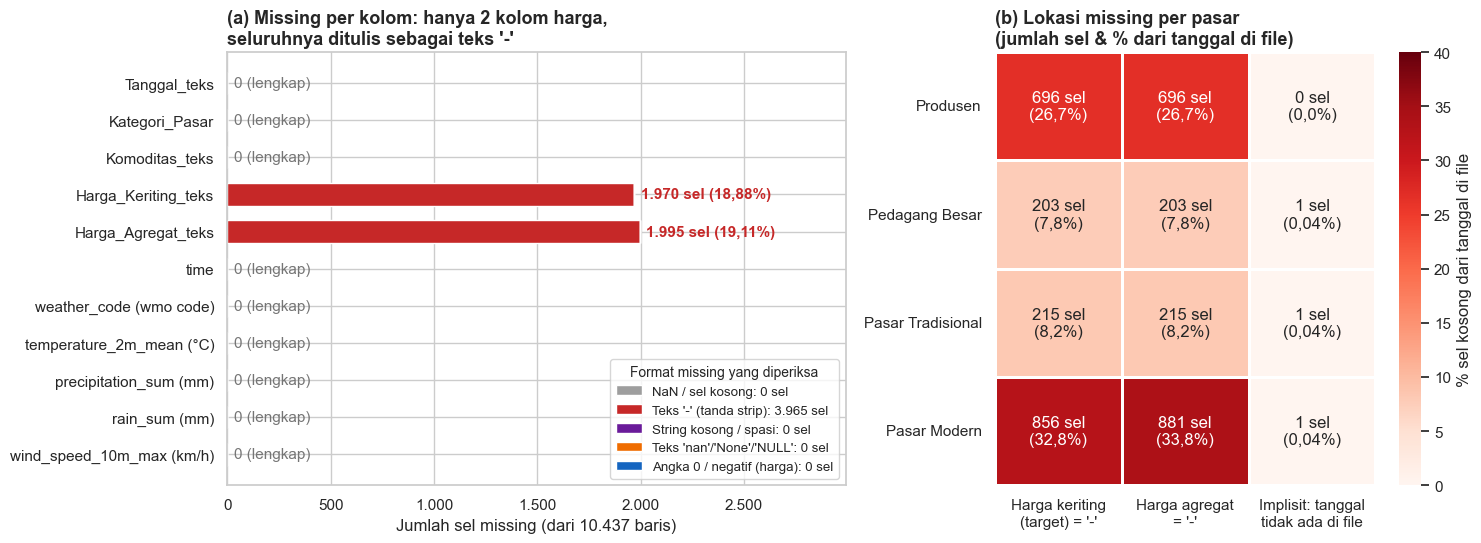

In [7]:
# VISUALISASI: (a) missing per kolom menurut format, (b) lokasi missing per pasar
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
kolom_urut = list(audit.index[::-1])
y = np.arange(len(kolom_urut))
kiri = np.zeros(len(kolom_urut))
warna_fmt = dict(zip(FORMAT_MISSING, ["#9e9e9e", "#c62828", "#6a1b9a", "#ef6c00", "#1565c0"]))
for fmt in FORMAT_MISSING:
    v = audit.loc[kolom_urut, fmt].values
    ax.barh(y, v, left=kiri, color=warna_fmt[fmt], height=0.6, label=f"{fmt}: {int(v.sum()):,} sel".replace(",", "."))
    kiri += v
for i, c in enumerate(kolom_urut):
    tot = int(audit.loc[c, "TOTAL missing"])
    teks = f"{tot:,} sel ({audit.loc[c, '% missing']:.2f}%)".replace(",", "X").replace(".", ",").replace("X", ".") if tot else "0 (lengkap)"
    ax.text(tot + 30, i, teks, va="center", fontsize=11, fontweight="bold" if tot else "normal", color="#c62828" if tot else "#757575")
ax.set_yticks(y, kolom_urut)
ax.set_xlim(0, audit["TOTAL missing"].max() * 1.5)
ax.xaxis.set_major_formatter(RIBUAN)
ax.set_xlabel(f"Jumlah sel missing (dari {len(mentah):,} baris)".replace(",", "."))
ax.set_title("(a) Missing per kolom: hanya 2 kolom harga,\nseluruhnya ditulis sebagai teks '-'", loc="left")
ax.legend(title="Format missing yang diperiksa", loc="lower right", fontsize=9.5, title_fontsize=10)

ax = axes[1]
kol_hm = ["Harga_Keriting_teks = '-'", "Harga_Agregat_teks = '-'", "implisit (tanggal tidak ada di file)"]
hm = rinci_pasar.loc[PASAR, kol_hm].astype(int)
pct = hm.div(rinci_pasar.loc[PASAR, "tanggal di file"], axis=0) * 100
annot = hm.astype(str) + " sel\n(" + pct.map(lambda v: (f"{v:.2f}" if 0 < v < 0.1 else f"{v:.1f}").replace(".", ",")) + "%)"
sns.heatmap(pct, annot=annot, fmt="", cmap="Reds", vmin=0, vmax=40, linewidths=2, linecolor="white",
            cbar_kws={"label": "% sel kosong dari tanggal di file"}, annot_kws={"fontsize": 12}, ax=ax)
ax.set_xticklabels(["Harga keriting\n(target) = '-'", "Harga agregat\n= '-'", "Implisit: tanggal\ntidak ada di file"], rotation=0)
ax.set_yticklabels(PASAR, rotation=0); ax.set_ylabel("")
ax.set_title("(b) Lokasi missing per pasar\n(jumlah sel & % dari tanggal di file)", loc="left")
plt.tight_layout(); plt.savefig(FIG / "01_missing_per_kolom.png"); plt.show()

**Rincian per pasar (kolom harga):**

| Pasar | Tanggal di file | `Harga_Keriting_teks` = `'-'` | `Harga_Agregat_teks` = `'-'` | Implisit (tanggal tidak ada) |
|---|---|---|---|---|
| Produsen | 2.610 | 696 (26,67%) | 696 (26,67%) | 0 |
| Pedagang Besar | 2.609 | 203 (7,78%) | 203 (7,78%) | 1 |
| Pasar Tradisional | 2.609 | 215 (8,24%) | 215 (8,24%) | 1 |
| Pasar Modern | 2.609 | 856 (32,81%) | 881 (33,77%) | 1 |
| **Total** | **10.437** | **1.970 (18,88%)** | **1.995 (19,11%)** | **3** |

- **Selisih 25 sel** antara kolom agregat dan keriting berasal **seluruhnya dari Pasar Modern**: pada 25 hari
  (24-04-2024 s.d. 22-07-2026) baris induk `Cabai Merah` kosong walaupun `Cabai Merah Keriting` terisi.
  Kebalikannya (keriting kosong tetapi agregat terisi) tidak pernah terjadi.
- **Missing implisit (3 sel):** tanggal 21-10-2026 hanya ada di file Produsen. Saat data dibuat lebar per tanggal
  (Langkah 2), Pedagang Besar, Pasar Tradisional, dan Pasar Modern otomatis kosong 1 hari pada tanggal itu. Inilah
  sebabnya tabel Langkah 2 menampilkan Pasar Tradisional **216** = 215 sel `'-'` + 1 tanggal implisit.

## Langkah 2 · Missing value

In [8]:
mentah["Tanggal"] = kunci
mentah["Harga_num"] = pd.to_numeric(mentah["Harga_Keriting_teks"].str.replace(",", "", regex=False).replace("-", np.nan),
                                    errors="coerce")
wide = mentah.pivot(index="Tanggal", columns="Kategori_Pasar", values="Harga_num")[PASAR]

per_tahun = wide.isna().groupby(wide.index.year).sum()
per_tahun.loc["TOTAL"] = per_tahun.sum()
print("Jumlah hari kerja TANPA data harga ('-') per pasar per tahun:")
display(per_tahun)

ketersediaan = pd.DataFrame({
    "data_pertama": wide.apply(lambda s: s.first_valid_index().date()),
    "data_terakhir": wide.apply(lambda s: s.last_valid_index().date()),
    "jumlah_kosong": wide.isna().sum(),
    "persen_kosong": (wide.isna().mean() * 100).round(1),
})
ketersediaan

Jumlah hari kerja TANPA data harga ('-') per pasar per tahun:


Kategori_Pasar,Produsen,Pedagang Besar,Pasar Tradisional,Pasar Modern
Tanggal,,,,
2016,52,52,52,52
2017,260,134,80,260
2018,191,4,14,261
2019,0,1,12,260
2020,0,6,20,0
2021,0,1,13,0
2022,1,2,14,1
2023,0,0,6,8
2024,1,3,4,1


,data_pertama,data_terakhir,jumlah_kosong,persen_kosong
Kategori_Pasar,,,,
Produsen,2018-09-25,2026-01-29,696,26.7
Pedagang Besar,2017-07-06,2026-10-20,204,7.8
Pasar Tradisional,2017-03-31,2026-10-20,216,8.3
Pasar Modern,2019-12-31,2026-10-20,857,32.8


Tabel per tahun memperlihatkan dua pola yang sangat berbeda:
- **Kosong panjang di awal/akhir.** Pasar Modern kosong penuh pada 2017–2019 (260–261 hari per tahun). Produsen kosong
  penuh pada 2017 dan berhenti setelah 29-01-2026 (189 hari kosong di 2026). Ini **missing struktural**: pasar tersebut
  memang belum atau tidak lagi disurvei PIHPS.
- **Kosong sedikit-sedikit di tengah periode.** Contohnya Pasar Tradisional 4–20 hari per tahun. Pola ini perlu dicek
  mekanismenya (sel berikutnya).
- **Catatan angka:** total di tabel ini sudah termasuk 1 tanggal implisit 21-10-2026 (lihat audit Langkah 1), misalnya
  Pasar Tradisional 216 = 215 sel `'-'` + 1.

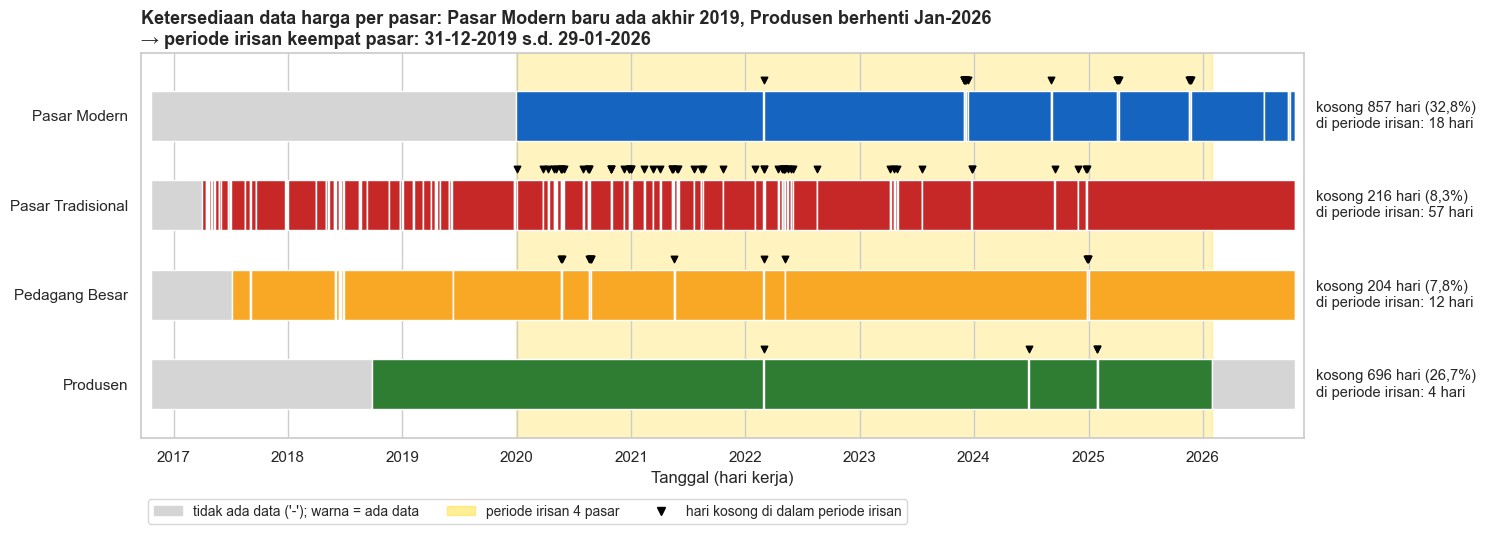

Periode irisan ke-4 pasar: 2019-12-31 s.d. 2026-01-29


In [9]:
awal = wide.notna().all(axis=1).idxmax()
akhir = wide.notna().all(axis=1)[::-1].idxmax()
fig, ax = plt.subplots(figsize=(15, 5))
D = mdates.date2num
ax.axvspan(D(awal), D(akhir), color="gold", alpha=0.25, zorder=0)
for i, m in enumerate(PASAR):
    ada = wide[m].notna()
    blok = (ada != ada.shift()).cumsum()
    for _, seg in ada.groupby(blok):
        x0, x1 = D(seg.index[0]), D(seg.index[-1] + pd.Timedelta(days=1))
        ax.broken_barh([(x0, x1 - x0)], (i - 0.28, 0.56), facecolors=WARNA[m] if seg.iloc[0] else "#d5d5d5")
    kosong_dlm = wide.loc[awal:akhir, m].isna()
    ax.scatter(D(kosong_dlm.index[kosong_dlm]), np.full(int(kosong_dlm.sum()), i + 0.40), marker="v", s=22, color="black", zorder=3)
    n_kos = int((~ada).sum())
    ax.text(1.01, i, f"kosong {n_kos} hari ({n_kos / len(ada) * 100:.1f}%)\ndi periode irisan: {int(kosong_dlm.sum())} hari".replace(".", ","),
            va="center", fontsize=10.5, transform=ax.get_yaxis_transform())
ax.set_yticks(range(len(PASAR)), PASAR)
ax.set_ylim(-0.6, len(PASAR) - 0.3)
ax.set_xlim(D(wide.index[0]) - 30, D(wide.index[-1]) + 30)
ax.xaxis_date(); ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlabel("Tanggal (hari kerja)")
ax.set_title(f"Ketersediaan data harga per pasar: Pasar Modern baru ada akhir 2019, Produsen berhenti Jan-2026\n"
             f"→ periode irisan keempat pasar: {awal:%d-%m-%Y} s.d. {akhir:%d-%m-%Y}", loc="left")
ax.legend(handles=[Patch(color="#d5d5d5", label="tidak ada data ('-'); warna = ada data"),
                   Patch(color="gold", alpha=0.4, label="periode irisan 4 pasar"),
                   Line2D([], [], marker="v", ls="", color="black", label="hari kosong di dalam periode irisan")],
          loc="upper left", ncol=3, fontsize=10, bbox_to_anchor=(0, -0.14))
ax.grid(axis="y", visible=False)
plt.savefig(FIG / "01_ketersediaan_data_per_pasar.png"); plt.show()
print("Periode irisan ke-4 pasar:", awal.date(), "s.d.", akhir.date())

In [10]:
# Mengapa data hilang? Bandingkan tanggal kosong dengan kalender hari libur nasional resmi (paket `holidays`)
libur = holidays.country_holidays("ID", years=range(2016, 2027))
tgl_libur = pd.to_datetime(list(libur.keys()))

def dekat_libur(t, jarak=2):
    return any(abs((t - h).days) <= jarak for h in tgl_libur)

periode = wide.loc[awal:akhir]
rows = []
for m in PASAR:
    kosong = periode.index[periode[m].isna()]
    rows.append({
        "Pasar": m,
        "hari kosong dlm periode": len(kosong),
        "tepat hari libur": int(sum(t in libur for t in kosong)),
        "<= 2 hari dari libur (cuti bersama)": int(sum(dekat_libur(t) for t in kosong)),
    })
mekanisme = pd.DataFrame(rows)
mekanisme["% terkait libur"] = (mekanisme["<= 2 hari dari libur (cuti bersama)"] / mekanisme["hari kosong dlm periode"] * 100).round(1)
base_rate = np.mean([dekat_libur(t) for t in periode.index]) * 100
print(f"Pembanding: hanya {base_rate:.1f}% dari SEMUA hari kerja dalam periode yang berada <= 2 hari dari libur nasional.")
mekanisme

Pembanding: hanya 20.7% dari SEMUA hari kerja dalam periode yang berada <= 2 hari dari libur nasional.


,Pasar,hari kosong dlm periode,tepat hari libur,<= 2 hari dari libur (cuti bersama),% terkait libur
0,Produsen,4,2,3,75.0
1,Pedagang Besar,12,2,7,58.3
2,Pasar Tradisional,57,43,56,98.2
3,Pasar Modern,18,1,3,16.7


**Mengapa data hilang di tengah periode?** Tanggal kosong dibandingkan dengan kalender libur nasional resmi Indonesia
(paket `holidays`).
- **Pasar Tradisional:** **98,2%** hari kosongnya (56 dari 57) jatuh tepat pada hari libur atau ≤ 2 hari darinya
  (cuti bersama). Secara umum hanya **20,7%** hari kerja yang dekat libur. Jadi kosong di sini **bukan acak**: pasar
  tradisional tidak disurvei saat libur. Ini termasuk missing *struktural / bergantung kalender*.
- **Pasar Modern:** hanya 16,7% yang terkait libur. Kosongnya berupa blok beberapa hari berturut-turut (misalnya akhir
  Nov–Des 2023 dan awal Apr 2025), yang lebih mirip gangguan pelaporan acak.
- **Produsen (4 hari) dan Pedagang Besar (12 hari):** jumlahnya sangat kecil.

In [11]:
# Contoh: tanggal kosong Pasar Tradisional beserta nama hari liburnya
kosong_trad = periode.index[periode["Pasar Tradisional"].isna()]
contoh = pd.DataFrame({"Tanggal": kosong_trad.date,
                       "Hari": kosong_trad.dayofweek.map(dict(enumerate(["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]))),
                       "Libur terdekat (<=2 hari)": [next((f"{h:%d-%m-%Y} {libur[h]}" for h in tgl_libur if abs((t-h).days) <= 2), "-") for t in kosong_trad]})
contoh.head(15)

,Tanggal,Hari,Libur terdekat (<=2 hari)
0,2020-01-01,Rabu,01-01-2020 Tahun Baru Masehi
1,2020-03-25,Rabu,25-03-2020 Hari Suci Nyepi
2,2020-04-10,Jumat,10-04-2020 Wafat Yesus Kristus
3,2020-05-01,Jumat,01-05-2020 Hari Buruh Internasional
4,2020-05-07,Kamis,07-05-2020 Hari Raya Waisak
5,2020-05-21,Kamis,21-05-2020 Kenaikan Yesus Kristus
6,2020-05-22,Jumat,24-05-2020 Hari Raya Idul Fitri
7,2020-05-25,Senin,24-05-2020 Hari Raya Idul Fitri
8,2020-06-01,Senin,01-06-2020 Hari Lahir Pancasila
9,2020-07-31,Jumat,31-07-2020 Hari Raya Idul Adha


In [12]:
# Uji strategi imputasi secara empiris: sembunyikan 5% harga yang DIKETAHUI, isi dengan tiap strategi, ukur galat
rng = np.random.default_rng(RANDOM_STATE)
strategi = ["Forward-fill per pasar", "Interpolasi linear per pasar", "Median per pasar", "Median global"]
err = {s: [] for s in strategi}
ape = {s: [] for s in strategi}
median_global = periode.stack().median()
for m in PASAR:
    s = periode[m].copy()
    idx_known = np.where(s.notna())[0]
    idx_mask = rng.choice(idx_known[1:-1], size=int(0.05 * len(idx_known)), replace=False)
    s_mask = s.copy()
    s_mask.iloc[idx_mask] = np.nan
    truth = s.iloc[idx_mask].values
    pred = {
        "Forward-fill per pasar": s_mask.ffill(),
        "Interpolasi linear per pasar": s_mask.interpolate(),
        "Median per pasar": s_mask.fillna(s_mask.median()),
        "Median global": s_mask.fillna(median_global),
    }
    for k, v in pred.items():
        e = np.abs(v.iloc[idx_mask].values - truth)
        err[k].append(e)
        ape[k].append(e / truth * 100)
uji_imputasi = pd.DataFrame({
    "MAE (Rp/kg)": {k: round(float(np.concatenate(v).mean()), 0) for k, v in err.items()},
    "MAPE (%)": {k: round(float(np.concatenate(v).mean()), 2) for k, v in ape.items()},
    "Memakai data masa depan?": dict(zip(strategi, ["Tidak", "Ya (nilai sesudahnya)", "Ya (median seluruh periode)", "Ya (median seluruh periode)"])),
})
print("Jumlah nilai yang disembunyikan:", sum(len(v) for v in err["Median global"]))
uji_imputasi.sort_values("MAE (Rp/kg)")

Jumlah nilai yang disembunyikan: 311


,MAE (Rp/kg),MAPE (%),Memakai data masa depan?
Interpolasi linear per pasar,1189.0,3.29,Ya (nilai sesudahnya)
Forward-fill per pasar,1469.0,3.60,Tidak
Median per pasar,12010.0,31.21,Ya (median seluruh periode)
Median global,13817.0,42.61,Ya (median seluruh periode)


**Memilih strategi imputasi berdasarkan bukti.** Sebanyak 311 harga yang diketahui (5%) sengaja disembunyikan, lalu diisi
ulang dengan 4 strategi.

| Unsur | Penjelasan |
|---|---|
| **Apa** | Harga keriting yang kosong di dalam periode bersih diisi dengan **forward-fill per Kategori_Pasar**, yaitu harga hari kerja terakhir yang dilaporkan pasar yang sama. Setiap baris yang diisi diberi penanda `Is_Imputasi = 1`. |
| **Mengapa** | Median per pasar (MAE Rp12.010) dan median global (Rp13.817) ditolak karena galatnya **8–9 kali lebih besar**: harga cabai bergerak mengikuti waktu, bukan berkisar di satu nilai tengah. Interpolasi linear memang sedikit lebih akurat (MAPE 3,29% vs 3,60%), tetapi ditolak karena **memakai harga sesudah hari kosong**. Data ini akan dipakai untuk memprediksi harga ke depan, jadi informasi masa depan tidak boleh masuk ke data latih. Forward-fill juga sesuai kenyataan: saat pasar libur, harga terakhir dianggap masih berlaku. |
| **Arti** | Setiap harga yang diisi berasal dari harga nyata pasar yang sama beberapa hari sebelumnya, bukan dari pasar lain atau dari rata-rata. |
| **Pengaruh** | Lihat sel berikut dan Langkah 7: missing turun menjadi 0%, sementara median dan mean hampir tidak bergeser. |

In [13]:
# TINDAKAN missing value
n_awal_rows = len(mentah)
luar = (mentah["Tanggal"] < awal) | (mentah["Tanggal"] > akhir)
print(f"Baris di luar periode irisan (dibuang): {luar.sum():,} dari {n_awal_rows:,}")

df = mentah.loc[~luar].copy()
df["Harga_Agregat_num"] = pd.to_numeric(df["Harga_Agregat_teks"].str.replace(",", "", regex=False).replace("-", np.nan), errors="coerce")
df = df.sort_values(["Kategori_Pasar", "Tanggal"])
df["Is_Imputasi"] = df["Harga_num"].isna().astype(int)
n_imp = df.groupby("Kategori_Pasar")["Is_Imputasi"].sum().reindex(PASAR)
n_imp_agregat = df["Harga_Agregat_num"].isna().groupby(df["Kategori_Pasar"]).sum().reindex(PASAR)
df["Harga_num"] = df.groupby("Kategori_Pasar")["Harga_num"].ffill()
df["Harga_Agregat_num"] = df.groupby("Kategori_Pasar")["Harga_Agregat_num"].ffill()
print("Harga keriting diisi forward-fill per pasar:", n_imp.to_dict(), "| total", int(n_imp.sum()))
print("Harga agregat diisi forward-fill per pasar:", n_imp_agregat.to_dict(), "| total", int(n_imp_agregat.sum()))
print("Sisa missing harga:", int(df["Harga_num"].isna().sum()), "| agregat:", int(df["Harga_Agregat_num"].isna().sum()))

log.append(["2a. Missing struktural (periode)", "Semua kolom", int(luar.sum()),
            f"Hapus baris di luar {awal:%d-%m-%Y} s.d. {akhir:%d-%m-%Y}",
            "Pasar belum disurvei / berhenti disurvei; mengisi = mengarang data"])
log.append(["2b. Missing hari libur", "Harga_Cabai_Merah_Keriting", int(n_imp.sum()),
            "Forward-fill per Kategori_Pasar + kolom penanda Is_Imputasi",
            f"{mekanisme['% terkait libur'].min():.0f}-{mekanisme['% terkait libur'].max():.0f}% kosong terjadi di sekitar libur nasional; ffill tidak memakai data masa depan"])
log.append(["2b. Missing hari libur", "Harga_Cabai_Merah_Agregat", int(n_imp_agregat.sum()),
            "Forward-fill per Kategori_Pasar (kolom kandidat leakage, diuji di Tahap 4)",
            f"Sama dengan harga keriting + {int(n_imp_agregat.sum() - n_imp.sum())} sel yang kosong hanya di agregat Pasar Modern"])

Baris di luar periode irisan (dibuang): 4,085 dari 10,437
Harga keriting diisi forward-fill per pasar: {'Produsen': 4, 'Pedagang Besar': 12, 'Pasar Tradisional': 57, 'Pasar Modern': 18} | total 91
Harga agregat diisi forward-fill per pasar: {'Produsen': 4, 'Pedagang Besar': 12, 'Pasar Tradisional': 57, 'Pasar Modern': 42} | total 115
Sisa missing harga: 0 | agregat: 0


| Unsur | Penjelasan |
|---|---|
| **Apa** | (a) Membuang **4.085 baris** di luar periode **31-12-2019 s.d. 29-01-2026**, yaitu periode ketika ke-4 pasar sama-sama punya data asli. (b) Mengisi sel kosong di dalam periode dengan forward-fill per pasar: **91 harga keriting** (Produsen 4, Pedagang Besar 12, Pasar Tradisional 57, Pasar Modern 18) dan **115 harga agregat** (sama, kecuali Pasar Modern 42). |
| **Mengapa** | Sebelum 31-12-2019, Pasar Modern belum pernah disurvei. Setelah 29-01-2026, Produsen 188 hari kerja berturut-turut kosong. Mengisi periode sepanjang itu sama dengan **mengarang data**, dan nilai Pasar Modern tahun 2017 tidak bisa ditebak dari apa pun. |
| **Arti** | Dataset bersih hanya memuat tanggal saat seluruh rantai pasok (petani → grosir → pasar → supermarket) teramati. Perbandingan antarpasar jadi adil karena periodenya sama. |
| **Pengaruh** | Baris turun dari 10.437 menjadi **6.352** (1.588 hari kerja × 4 pasar). Missing kedua kolom harga turun dari **18,88% / 19,11% menjadi 0%**. Rincian per kolom × pasar ada di sel berikut. |

total sel '-' (mentah)  di luar periode -> baris dibuang  di dalam periode -> forward-fill  sisa missing
kolom                      pasar                                                                                                                      
Harga_Cabai_Merah_Keriting Produsen                              696                               692                                 4             0
                           Pedagang Besar                        203                               191                                12             0
                           Pasar Tradisional                     215                               158                                57             0
                           Pasar Modern                          856                               838                                18             0
                           TOTAL                                1970                              1879                                91             0
Harga_Cabai_Merah_Agregat  Produsen                              696                               692                                 4             0
                           Pedagang Besar                        203                               191                                12             0
                           Pasar Tradisional                     215                               158                                57             0
                           Pasar Modern                          881                               839                                42             0
                           TOTAL                                1995                              1880                               115             0

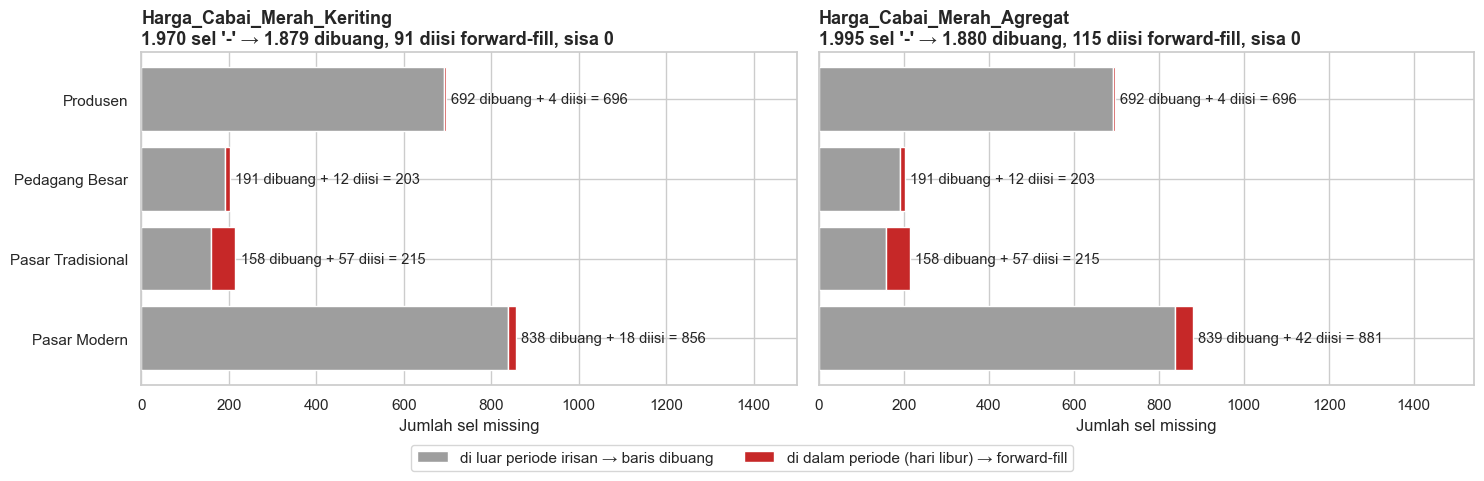

In [14]:
# RINGKASAN PENANGANAN: ke mana perginya setiap sel missing? (per kolom harga x per pasar)
rows = []
for kolom, kosong, kol_bersih in [("Harga_Cabai_Merah_Keriting", kosong_k, "Harga_num"), ("Harga_Cabai_Merah_Agregat", kosong_a, "Harga_Agregat_num")]:
    for m in PASAR:
        km = kosong & mentah["Kategori_Pasar"].eq(m)
        rows.append({"kolom": kolom, "pasar": m, "total sel '-' (mentah)": int(km.sum()),
                     "di luar periode -> baris dibuang": int((km & luar).sum()),
                     "di dalam periode -> forward-fill": int((km & ~luar).sum()),
                     "sisa missing": int(df.loc[df["Kategori_Pasar"] == m, kol_bersih].isna().sum())})
penanganan = pd.DataFrame(rows)
bagian = []
for kolom, g in penanganan.groupby("kolom", sort=False):
    bagian += [g, g[g.columns[2:]].sum().to_frame().T.assign(kolom=kolom, pasar="TOTAL")]
penanganan_tampil = pd.concat(bagian).set_index(["kolom", "pasar"]).astype(int)
display(penanganan_tampil)
assert (penanganan["total sel '-' (mentah)"] == penanganan["di luar periode -> baris dibuang"] + penanganan["di dalam periode -> forward-fill"]).all()
assert penanganan["sisa missing"].sum() == 0

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
for ax, (kolom, g) in zip(axes, penanganan.groupby("kolom", sort=False)):
    g = g.set_index("pasar").reindex(PASAR[::-1])
    a = g["di luar periode -> baris dibuang"]; b = g["di dalam periode -> forward-fill"]
    ax.barh(g.index, a, color="#9e9e9e", label="di luar periode irisan → baris dibuang")
    ax.barh(g.index, b, left=a, color="#c62828", label="di dalam periode (hari libur) → forward-fill")
    for i, m in enumerate(g.index):
        ax.text(a[m] + b[m] + 12, i, f"{a[m]} dibuang + {b[m]} diisi = {a[m] + b[m]}", va="center", fontsize=10.5)
    ax.set_xlim(0, (a + b).max() * 1.75)
    rb = lambda v: f"{int(v):,}".replace(",", ".")
    ax.set_title(f"{kolom}\n{rb((a + b).sum())} sel '-' → {rb(a.sum())} dibuang, {rb(b.sum())} diisi forward-fill, sisa 0", loc="left")
    ax.set_xlabel("Jumlah sel missing")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, fontsize=11, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(); plt.savefig(FIG / "01_penanganan_missing.png"); plt.show()

**Ringkasan penanganan missing per kolom:**

| Kolom | Format | Total sel missing | Di luar periode → baris dibuang | Di dalam periode → forward-fill | Sisa |
|---|---|---|---|---|---|
| `Harga_Cabai_Merah_Keriting` (target) | `'-'` | 1.970 | 1.879 | **91** (Produsen 4, PB 12, Tradisional 57, Modern 18) | **0** |
| `Harga_Cabai_Merah_Agregat` | `'-'` | 1.995 | 1.880 | **115** (Produsen 4, PB 12, Tradisional 57, Modern 42) | **0** |
| 3 sel implisit (21-10-2026) | tanggal tidak ada | 3 | 3 (di luar periode) | 0 | **0** |
| 9 kolom lain (tanggal, pasar, komoditas, cuaca) | – | 0 | – | – | **0** |

Hanya forward-fill harga keriting yang diberi penanda `Is_Imputasi = 1` (target). Kolom agregat juga diisi
dengan cara yang sama, tetapi kolom ini nantinya dibuang sebagai *leakage* di Tahap 4.

## Langkah 3 · Duplikat

In [15]:
dup = {}
dup["Duplikat persis (semua kolom)"] = int(mentah.drop(columns=["Tanggal", "Harga_num"]).duplicated().sum())
dup["Duplikat kunci (Tanggal_teks, Pasar)"] = int(mentah.duplicated(["Tanggal_teks", "Kategori_Pasar"]).sum())
tgl_rapi = mentah["Tanggal_teks"].str.replace(" ", "", regex=False)
dup["Duplikat kunci setelah teks tanggal dirapikan"] = int(pd.DataFrame({"t": tgl_rapi, "p": mentah["Kategori_Pasar"]}).duplicated().sum())
dup["Duplikat tanggal di CSV cuaca"] = int(cuaca_raw["time"].duplicated().sum())
dup["Kolom cuaca identik: rain_sum vs precipitation_sum (% baris sama)"] = float((cuaca_raw["rain_sum (mm)"] == cuaca_raw["precipitation_sum (mm)"]).mean() * 100)
sama_induk = (mentah["Harga_Keriting_teks"] == mentah["Harga_Agregat_teks"]).groupby(mentah["Kategori_Pasar"]).mean().mul(100).round(1)
display(pd.Series(dup, name="hasil"))
print("Baris induk 'I - Cabai Merah' identik dengan baris 'Cabai Merah Keriting' (% hari):")
print(sama_induk.reindex(PASAR).to_string())

Duplikat persis (semua kolom)                                          0.0
Duplikat kunci (Tanggal_teks, Pasar)                                   0.0
Duplikat kunci setelah teks tanggal dirapikan                          0.0
Duplikat tanggal di CSV cuaca                                          0.0
Kolom cuaca identik: rain_sum vs precipitation_sum (% baris sama)    100.0
Name: hasil, dtype: float64

Baris induk 'I - Cabai Merah' identik dengan baris 'Cabai Merah Keriting' (% hari):
Kategori_Pasar
Produsen             100.0
Pedagang Besar        99.2
Pasar Tradisional    100.0
Pasar Modern          73.3


In [16]:
cuaca = cuaca_raw.drop(columns=["rain_sum (mm)"])
log.append(["3. Kolom duplikat", "rain_sum (mm)", len(cuaca_raw), "Kolom dihapus",
            "100% identik dengan precipitation_sum (mm); informasi ganda"])
log.append(["3. Duplikat baris/kunci", "Tanggal, Kategori_Pasar", 0, "Diperiksa, tidak ada yang dihapus",
            "0 duplikat persis maupun kunci (juga setelah teks tanggal dirapikan)"])
log.append(["3. Kolom hampir duplikat", "Harga_Cabai_Merah_Agregat", int(len(df)), "Dipertahankan sebagai kandidat; diuji leakage di Tahap 4",
            "Baris induk 'Cabai Merah' identik dgn target di sebagian besar hari (agregat hari yang sama)"])
print("Kolom cuaca tersisa:", list(cuaca.columns))

Kolom cuaca tersisa: ['time', 'weather_code (wmo code)', 'temperature_2m_mean (°C)', 'precipitation_sum (mm)', 'wind_speed_10m_max (km/h)']


| Unsur | Penjelasan |
|---|---|
| **Apa** | Memeriksa duplikat persis, duplikat kunci `(Tanggal, Kategori_Pasar)` (juga setelah spasi pada teks tanggal dihapus), duplikat tanggal di CSV cuaca, dan duplikat kolom. |
| **Mengapa** | Duplikat kunci membuat satu hari terhitung dua kali. Kolom kembar menambah informasi palsu dan memicu multikolinearitas. |
| **Arti** | Ada **0** duplikat baris maupun kunci. Kolom `rain_sum (mm)` **100% identik** dengan `precipitation_sum (mm)`. Baris induk `Cabai Merah` identik dengan `Cabai Merah Keriting` pada 100% hari di Produsen dan Pasar Tradisional, 99,2% di Pedagang Besar, dan 73,3% di Pasar Modern. |
| **Pengaruh** | Kolom `rain_sum (mm)` dihapus, sehingga kolom cuaca berkurang dari 6 menjadi 5. Harga agregat **tidak dihapus** di sini. Kolom ini diberi nama `Harga_Cabai_Merah_Agregat` dan diuji sebagai kandidat **data leakage** di Tahap 4, karena berisi harga hari yang sama dan hampir identik dengan target. |

## Langkah 4 · Tipe data & format

In [17]:
contoh_format = pd.DataFrame({
    "Masalah": ["Tanggal berupa teks berspasi", "Harga berupa teks dgn koma ribuan", "Hari tanpa laporan ditulis '-'",
                "Nama komoditas berspasi di akhir", "Nama kolom cuaca berisi satuan & simbol", "Penamaan file/pasar tidak seragam"],
    "Contoh sebelum": [repr(mentah["Tanggal_teks"].iloc[0]), repr(mentah.loc[mentah["Harga_Keriting_teks"].str.contains(",", na=False), "Harga_Keriting_teks"].iloc[0]),
                       "'-'", repr(mentah["Komoditas_teks"].iloc[0]), repr(cuaca_raw.columns[2]), "'pedagang tradisional', 'pasar modern 10n tahun'"],
    "Jumlah terdampak": [int(mentah["Tanggal_teks"].str.contains(" ").sum()),
                         int(mentah["Harga_Keriting_teks"].str.contains(",", na=False).sum() + mentah["Harga_Agregat_teks"].str.contains(",", na=False).sum()),
                         int((mentah["Harga_Keriting_teks"].str.strip() == "-").sum()),
                         int(mentah["Komoditas_teks"].str.endswith(" ").sum()),
                         int(sum("(" in c for c in cuaca_raw.columns)), 4],
})
contoh_format

,Masalah,Contoh sebelum,Jumlah terdampak
0,Tanggal berupa teks berspasi,'20/ 10/ 2016',10437
1,Harga berupa teks dgn koma ribuan,"'28,500'",16909
2,Hari tanpa laporan ditulis '-','-',1970
3,Nama komoditas berspasi di akhir,'Cabai Merah Keriting ',10437
4,Nama kolom cuaca berisi satuan & simbol,'temperature_2m_mean (°C)',5
5,Penamaan file/pasar tidak seragam,"'pedagang tradisional', 'pasar modern 10n tahun'",4


In [18]:
print("Tipe SEBELUM:")
print(df[["Tanggal_teks", "Komoditas_teks", "Harga_Keriting_teks", "Harga_Agregat_teks"]].dtypes.to_string())

cuaca = cuaca.rename(columns={
    "time": "Tanggal", "weather_code (wmo code)": "Kode_Cuaca_WMO", "temperature_2m_mean (°C)": "Suhu_Rata2_C",
    "precipitation_sum (mm)": "Curah_Hujan_mm", "wind_speed_10m_max (km/h)": "Kecepatan_Angin_Maks_kmh"})
cuaca["Tanggal"] = pd.to_datetime(cuaca["Tanggal"])

bersih = pd.DataFrame({
    "Tanggal": df["Tanggal"].values,
    "Kategori_Pasar": pd.Categorical(df["Kategori_Pasar"].values, categories=PASAR),
    "Komoditas": df["Komoditas_teks"].str.strip().values,
    "Harga_Cabai_Merah_Keriting": df["Harga_num"].round().astype("int64").values,
    "Harga_Cabai_Merah_Agregat": df["Harga_Agregat_num"].round().astype("int64").values,
    "Is_Imputasi": df["Is_Imputasi"].values,
}).merge(cuaca, on="Tanggal", how="left")
print("\nTipe SESUDAH:")
print(bersih.dtypes.to_string())
print("\nNilai unik Komoditas sesudah strip:", bersih["Komoditas"].unique())
log.append(["4. Tipe & format", "Tanggal", int(mentah['Tanggal_teks'].str.contains(' ').sum()), "Hapus spasi, parse dd/mm/yyyy -> datetime", "Header tanggal berupa teks '20/ 10/ 2016'"])
log.append(["4. Tipe & format", "Harga_Cabai_Merah_Keriting, Harga_Cabai_Merah_Agregat", int(contoh_format['Jumlah terdampak'].iloc[1]), "Hapus koma ribuan, '-' -> NaN, ubah ke int64", "Angka tersimpan sebagai teks sehingga tidak bisa dihitung"])
log.append(["4. Tipe & format", "Komoditas", int(mentah['Komoditas_teks'].str.endswith(' ').sum()), "strip() spasi di akhir", "'Cabai Merah Keriting ' vs 'Cabai Merah Keriting' dianggap berbeda"])
log.append(["4. Tipe & format", "Kolom cuaca", 5, "Ganti nama kolom (tanpa satuan/simbol), time -> datetime", "Nama asli berisi '(°C)', '(mm)' menyulitkan pemanggilan kolom"])
log.append(["4. Tipe & format", "Kategori_Pasar", 4, "Label seragam dari nama file + tipe category berurutan", "Nama file tidak konsisten ('pedagang tradisional', '10n tahun')"])

Tipe SEBELUM:
Tanggal_teks           object
Komoditas_teks         object
Harga_Keriting_teks    object
Harga_Agregat_teks     object

Tipe SESUDAH:
Tanggal                       datetime64[ns]
Kategori_Pasar                      category
Komoditas                             object
Harga_Cabai_Merah_Keriting             int64
Harga_Cabai_Merah_Agregat              int64
Is_Imputasi                            int32
Kode_Cuaca_WMO                         int64
Suhu_Rata2_C                         float64
Curah_Hujan_mm                       float64
Kecepatan_Angin_Maks_kmh             float64

Nilai unik Komoditas sesudah strip: ['Cabai Merah Keriting']


| Unsur | Penjelasan |
|---|---|
| **Apa** | (1) Header tanggal `'20/ 10/ 2016'` dihapus spasinya lalu diubah ke `datetime`. (2) **16.909 sel** harga berkoma ribuan (`'28,500'`) diubah ke `int64`, dan `'-'` menjadi NaN. (3) `'Cabai Merah Keriting '` dirapikan dengan `strip()`. (4) Kolom cuaca diganti nama tanpa satuan atau simbol. (5) Label pasar diseragamkan, karena nama file tidak konsisten. |
| **Mengapa** | Harga bertipe teks tidak bisa dihitung rata-ratanya. Tanggal bertipe teks tidak bisa diurutkan secara kronologis dan tidak bisa digabung dengan data cuaca. Spasi tersembunyi membuat label yang sama terbaca sebagai kategori berbeda. |
| **Arti** | Semua kolom sekarang bertipe sesuai isinya: tanggal `datetime64`, harga `int64`, cuaca `float64`, pasar `category`. |
| **Pengaruh** | Data bisa dihitung, diurutkan, dan digabung. Kolom `Komoditas` tinggal **1 nilai unik** (konstan) dan tetap disimpan hanya sebagai identitas data. |

## Langkah 5 · Nilai tidak masuk akal (aturan domain)

In [19]:
WMO_VALID = {0, 1, 2, 3, 45, 48, 51, 53, 55, 56, 57, 61, 63, 65, 66, 67, 71, 73, 75, 77, 80, 81, 82, 85, 86, 95, 96, 99}
aturan = {
    "Harga keriting > 0": ~(bersih["Harga_Cabai_Merah_Keriting"] > 0),
    "Harga keriting <= Rp250.000/kg": bersih["Harga_Cabai_Merah_Keriting"] > 250_000,
    "Harga agregat > 0": ~(bersih["Harga_Cabai_Merah_Agregat"] > 0),
    "Suhu rata-rata Medan 15-40 °C": ~bersih["Suhu_Rata2_C"].between(15, 40),
    "Curah hujan 0-300 mm/hari": ~bersih["Curah_Hujan_mm"].between(0, 300),
    "Angin maks 0-120 km/jam": ~bersih["Kecepatan_Angin_Maks_kmh"].between(0, 120),
    "Kode cuaca termasuk kode WMO resmi": ~bersih["Kode_Cuaca_WMO"].isin(WMO_VALID),
    "Tanggal hari kerja (Senin-Jumat)": bersih["Tanggal"].dt.dayofweek >= 5,
    "Cuaca tersedia untuk tanggal harga": bersih["Suhu_Rata2_C"].isna(),
}
domain = pd.DataFrame({"jumlah_pelanggaran": {k: int(v.sum()) for k, v in aturan.items()}})
domain["status"] = np.where(domain["jumlah_pelanggaran"] == 0, "Lolos", "Perlu ditangani")
extra_cols = sorted(set(mentah.loc[mentah["Kategori_Pasar"] == "Produsen", "Tanggal"]) - set(mentah.loc[mentah["Kategori_Pasar"] == "Pasar Modern", "Tanggal"]))
print("Tanggal yang hanya ada di file Produsen (di luar rentang file lain):", [t.date() for t in extra_cols])
domain

Tanggal yang hanya ada di file Produsen (di luar rentang file lain): [datetime.date(2026, 10, 21)]


,jumlah_pelanggaran,status
Harga keriting > 0,0,Lolos
Harga keriting <= Rp250.000/kg,0,Lolos
Harga agregat > 0,0,Lolos
Suhu rata-rata Medan 15-40 °C,0,Lolos
Curah hujan 0-300 mm/hari,0,Lolos
Angin maks 0-120 km/jam,0,Lolos
Kode cuaca termasuk kode WMO resmi,0,Lolos
Tanggal hari kerja (Senin-Jumat),0,Lolos
Cuaca tersedia untuk tanggal harga,0,Lolos


In [20]:
log.append(["5. Aturan domain", "Harga, Suhu, Curah_Hujan, Angin, Kode_Cuaca, Tanggal", int(domain['jumlah_pelanggaran'].sum()),
            "Diperiksa 9 aturan; tidak ada nilai yang diubah", "Semua nilai berada dalam rentang fisik/ekonomi yang wajar"])
log.append(["5. Tanggal di luar rentang", "Tanggal (file Produsen)", len(extra_cols), "Ikut terbuang bersama langkah 2a",
            "Kolom 21/10/2026 hanya ada di file Produsen dan isinya '-'"])

| Unsur | Penjelasan |
|---|---|
| **Apa** | Menetapkan **9 aturan domain**: harga > 0 dan ≤ Rp250.000/kg, suhu Medan 15–40 °C, hujan 0–300 mm/hari, angin 0–120 km/jam, kode cuaca harus kode WMO resmi, tanggal harus hari kerja, dan setiap tanggal harga harus punya data cuaca. |
| **Mengapa** | Nilai yang mustahil secara fisik atau ekonomi pasti salah input dan akan merusak model. Batas Rp250.000/kg dipilih jauh di atas rekor harga cabai nasional, sehingga hanya menangkap kesalahan, bukan lonjakan yang sah. |
| **Arti** | Ada **0 pelanggaran**. Satu-satunya anomali tanggal adalah kolom 21/10/2026 yang hanya ada di file Produsen dan isinya `'-'`. |
| **Pengaruh** | Tidak ada nilai yang diubah. Kolom tanggal ekstra itu sudah ikut terbuang di Langkah 2a. |

## Langkah 6 · Outlier (IQR & Z-score)

In [21]:
def ringkas_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std()
    return pd.Series({"Q1": q1, "Q3": q3, "batas_bawah": lo, "batas_atas": hi,
                      "outlier_IQR": int(((s < lo) | (s > hi)).sum()), "outlier_Z>3": int((z.abs() > 3).sum()),
                      "skewness": round(s.skew(), 2)})

out_harga = bersih.groupby("Kategori_Pasar", observed=True)["Harga_Cabai_Merah_Keriting"].apply(ringkas_outlier).unstack()
out_cuaca = pd.DataFrame({c: ringkas_outlier(cuaca.loc[cuaca["Tanggal"].between(awal, akhir), c])
                          for c in ["Suhu_Rata2_C", "Curah_Hujan_mm", "Kecepatan_Angin_Maks_kmh"]}).T
print("Outlier harga per pasar:")
display(out_harga)
print("Outlier cuaca harian (periode bersih):")
display(out_cuaca)

Outlier harga per pasar:


,Q1,Q3,batas_bawah,batas_atas,outlier_IQR,outlier_Z>3,skewness
Kategori_Pasar,,,,,,,
Produsen,17000.0,33000.0,-7000.0,57000.0,108.0,0.0,1.49
Pedagang Besar,21000.0,38000.0,-4500.0,63500.0,100.0,20.0,1.43
Pasar Tradisional,26600.0,44700.0,-550.0,71850.0,94.0,37.0,1.44
Pasar Modern,40050.0,58850.0,11850.0,87050.0,70.0,30.0,1.48


Outlier cuaca harian (periode bersih):


,Q1,Q3,batas_bawah,batas_atas,outlier_IQR,outlier_Z>3,skewness
Suhu_Rata2_C,25.2,26.400,23.4000,28.2000,25.0,15.0,0.20
Curah_Hujan_mm,3.7,18.100,-17.9000,39.7000,57.0,24.0,1.95
Kecepatan_Angin_Maks_kmh,8.8,11.875,4.1875,16.4875,29.0,18.0,0.53


In [22]:
# Membedakan KESALAHAN INPUT vs NILAI EKSTREM SAH.
# Aturan error: lonjakan 1 hari yang berbeda > 40% dari hari sebelum DAN sesudahnya, sementara hari sebelum & sesudah mirip (< 10%).
def cek_spike(g):
    s = g["Harga_Cabai_Merah_Keriting"].astype(float)
    prev, nxt = s.shift(1), s.shift(-1)
    spike = ((s / prev - 1).abs() > 0.4) & ((s / nxt - 1).abs() > 0.4) & ((nxt / prev - 1).abs() < 0.10)
    return g.loc[spike, ["Tanggal", "Kategori_Pasar", "Harga_Cabai_Merah_Keriting"]].assign(
        harga_sebelum=prev[spike].values, harga_sesudah=nxt[spike].values)

spikes = pd.concat([cek_spike(g) for _, g in bersih.groupby("Kategori_Pasar", observed=True)])
print("Kandidat kesalahan input (lonjakan 1 hari lalu kembali):", len(spikes))
display(spikes)

# Outlier IQR yang SAH: apakah bertahan beberapa hari & terjadi serentak di pasar lain?
iqr_flag = []
for m, g in bersih.groupby("Kategori_Pasar", observed=True):
    hi = out_harga.loc[m, "batas_atas"]
    flag = g.loc[g["Harga_Cabai_Merah_Keriting"] > hi, "Tanggal"]
    iqr_flag.append(pd.DataFrame({"Kategori_Pasar": m, "Tanggal": flag}))
iqr_flag = pd.concat(iqr_flag)
print("Outlier IQR (atas) per tahun-bulan:")
print(iqr_flag.groupby([iqr_flag["Tanggal"].dt.to_period("M"), "Kategori_Pasar"]).size().unstack(fill_value=0).to_string())

Kandidat kesalahan input (lonjakan 1 hari lalu kembali): 1


,Tanggal,Kategori_Pasar,Harga_Cabai_Merah_Keriting,harga_sebelum,harga_sesudah
2477,2023-05-29,Pasar Tradisional,30200,19400.0,21000.0


Outlier IQR (atas) per tahun-bulan:
Kategori_Pasar  Pasar Modern  Pasar Tradisional  Pedagang Besar  Produsen
Tanggal                                                                  
2022-06                   13                 14              11         4
2022-07                   21                 20              21        21
2022-08                   18                 17              18        23
2022-09                    8                  6              10        17
2023-11                    0                  1               0         0
2023-12                    0                  1               0         0
2024-03                    0                  2               5         0
2024-05                    0                  1               0         0
2025-09                    6                 12               9         4
2025-10                    4                 16              21        23
2025-11                    0                  2               2        16
20

**Membedakan kesalahan input dari nilai ekstrem yang sah.**
- **IQR menandai 372 harga** (Produsen 108, Pedagang Besar 100, Pasar Tradisional 94, Pasar Modern 70). Semuanya di sisi
  atas, dan hampir semuanya berkumpul pada **Jun–Sep 2022** dan **Sep–Nov 2025**. Pada periode itu ke-4 pasar naik
  **serentak** dan bertahan berminggu-minggu. Ini gejolak harga nyata, bukan salah ketik, sehingga **dipertahankan tanpa
  capping**, karena lonjakan seperti inilah yang paling penting untuk diprediksi.
- **Aturan kesalahan input:** harga melonjak > 40% dari hari sebelum *dan* sesudahnya, padahal hari sebelum dan
  sesudahnya mirip (< 10%). Aturan ini menemukan **1 kasus**: Pasar Tradisional 29-05-2023 = Rp30.200, di antara
  Rp19.400 dan Rp21.000. Pola naik 56% lalu turun lagi dalam sehari ini khas salah ketik, sehingga nilainya **diganti
  dengan harga hari sebelumnya** dan diberi penanda `Is_Imputasi = 1`.
- **Cuaca:** hujan memiliki 57 outlier IQR (skewness 1,95) dan angin 29. Keduanya kejadian cuaca nyata di Medan, jadi
  dipertahankan. Kemiringan distribusinya ditangani dengan transformasi di Tahap 3.

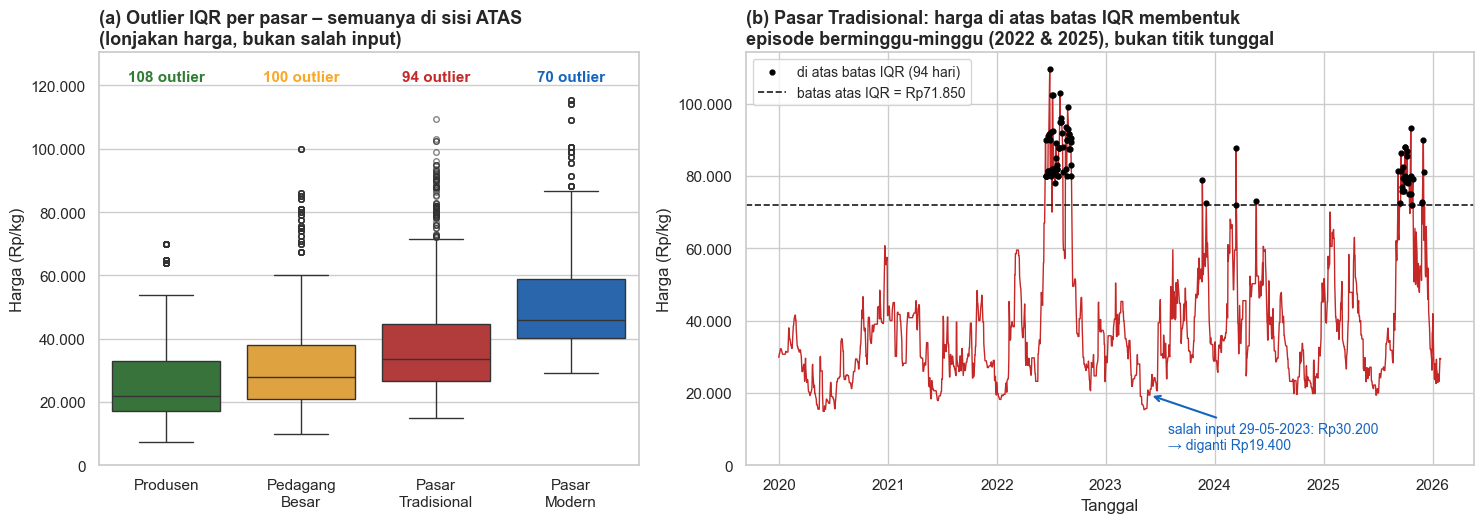

In [23]:
if len(spikes):
    for _, r in spikes.iterrows():
        mask = (bersih["Tanggal"] == r["Tanggal"]) & (bersih["Kategori_Pasar"] == r["Kategori_Pasar"])
        bersih.loc[mask, "Harga_Cabai_Merah_Keriting"] = int(r["harga_sebelum"])
        bersih.loc[mask, "Is_Imputasi"] = 1
log.append(["6. Outlier - kesalahan input", "Harga_Cabai_Merah_Keriting", len(spikes),
            "Diganti harga hari sebelumnya (forward-fill) + Is_Imputasi=1" if len(spikes) else "Tidak ada yang perlu diperbaiki",
            "Lonjakan 1 hari >40% lalu kembali ke level semula = pola salah ketik"])
log.append(["6. Outlier - ekstrem sah", "Harga_Cabai_Merah_Keriting", int(out_harga["outlier_IQR"].sum()),
            "Dipertahankan (tidak di-capping)", "Bertahan berminggu-minggu & serentak di beberapa pasar (gejolak harga nyata); ini justru pola yang harus diprediksi"])
log.append(["6. Outlier - ekstrem sah", "Curah_Hujan_mm, Kecepatan_Angin_Maks_kmh", int(out_cuaca.loc[['Curah_Hujan_mm', 'Kecepatan_Angin_Maks_kmh'], 'outlier_IQR'].sum()),
            "Dipertahankan; kemiringan ditangani transformasi di Tahap 3", "Hujan lebat/angin kencang adalah kejadian cuaca nyata di Medan"])

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1, 1.35]})
sns.boxplot(data=bersih, x="Kategori_Pasar", y="Harga_Cabai_Merah_Keriting", palette=WARNA, ax=axes[0],
            flierprops={"marker": "o", "markersize": 4, "alpha": .6})
ymax = bersih["Harga_Cabai_Merah_Keriting"].max()
for i, m in enumerate(PASAR):
    axes[0].text(i, ymax * 1.05, f"{int(out_harga.loc[m, 'outlier_IQR'])} outlier", ha="center", fontsize=11, fontweight="bold", color=WARNA[m])
axes[0].set_ylim(0, ymax * 1.13)
axes[0].set_xticks(range(len(PASAR)), [m.replace(" ", "\n") for m in PASAR])
axes[0].set_title("(a) Outlier IQR per pasar – semuanya di sisi ATAS\n(lonjakan harga, bukan salah input)", loc="left")
axes[0].set_xlabel(""); axes[0].set_ylabel("Harga (Rp/kg)"); axes[0].yaxis.set_major_formatter(RIBUAN)

trad = bersih[bersih["Kategori_Pasar"] == "Pasar Tradisional"]
batas = out_harga.loc["Pasar Tradisional", "batas_atas"]
lebih = trad["Harga_Cabai_Merah_Keriting"] > batas
axes[1].plot(trad["Tanggal"], trad["Harga_Cabai_Merah_Keriting"], color=WARNA["Pasar Tradisional"], lw=1)
axes[1].scatter(trad.loc[lebih, "Tanggal"], trad.loc[lebih, "Harga_Cabai_Merah_Keriting"], s=12, color="black", zorder=3,
                label=f"di atas batas IQR ({int(lebih.sum())} hari)")
axes[1].axhline(batas, ls="--", color="k", lw=1.2, label=f"batas atas IQR = Rp{batas:,.0f}".replace(",", "."))
for _, r in spikes[spikes["Kategori_Pasar"] == "Pasar Tradisional"].iterrows():
    axes[1].annotate(f"salah input {r['Tanggal']:%d-%m-%Y}: Rp{r['Harga_Cabai_Merah_Keriting']:,.0f}\n→ diganti Rp{r['harga_sebelum']:,.0f}".replace(",", "."),
                     xy=(r["Tanggal"], r["harga_sebelum"]), xytext=(r["Tanggal"] + pd.Timedelta(days=60), 4500),
                     fontsize=10, arrowprops=dict(arrowstyle="->", color="#1565c0", lw=1.5), color="#1565c0")
axes[1].set_title("(b) Pasar Tradisional: harga di atas batas IQR membentuk\nepisode berminggu-minggu (2022 & 2025), bukan titik tunggal", loc="left")
axes[1].set_xlabel("Tanggal"); axes[1].set_ylabel("Harga (Rp/kg)"); axes[1].yaxis.set_major_formatter(RIBUAN); axes[1].set_ylim(0, None)
axes[1].legend(loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "01_outlier_harga.png")
plt.show()

## Langkah 7 · Log cleaning & perbandingan sebelum vs sesudah

In [24]:
log_df = pd.DataFrame(log, columns=["langkah", "kolom", "jumlah_baris_terdampak", "tindakan", "alasan"])
log_df.to_csv(LAP / "log_cleaning.csv", index=False, encoding="utf-8-sig")
log_df

,langkah,kolom,jumlah_baris_terdampak,tindakan,alasan
0,2a. Missing struktural (periode),Semua kolom,4085,Hapus baris di luar 31-12-2019 s.d. 29-01-2026,Pasar belum disurvei / berhenti disurvei; meng...
1,2b. Missing hari libur,Harga_Cabai_Merah_Keriting,91,Forward-fill per Kategori_Pasar + kolom penand...,17-98% kosong terjadi di sekitar libur nasiona...
2,2b. Missing hari libur,Harga_Cabai_Merah_Agregat,115,Forward-fill per Kategori_Pasar (kolom kandida...,Sama dengan harga keriting + 24 sel yang koson...
3,3. Kolom duplikat,rain_sum (mm),3667,Kolom dihapus,100% identik dengan precipitation_sum (mm); in...
4,3. Duplikat baris/kunci,"Tanggal, Kategori_Pasar",0,"Diperiksa, tidak ada yang dihapus",0 duplikat persis maupun kunci (juga setelah t...
5,3. Kolom hampir duplikat,Harga_Cabai_Merah_Agregat,6352,Dipertahankan sebagai kandidat; diuji leakage ...,Baris induk 'Cabai Merah' identik dgn target d...
6,4. Tipe & format,Tanggal,10437,"Hapus spasi, parse dd/mm/yyyy -> datetime",Header tanggal berupa teks '20/ 10/ 2016'
7,4. Tipe & format,"Harga_Cabai_Merah_Keriting, Harga_Cabai_Merah_...",16909,"Hapus koma ribuan, '-' -> NaN, ubah ke int64",Angka tersimpan sebagai teks sehingga tidak bi...
8,4. Tipe & format,Komoditas,10437,strip() spasi di akhir,'Cabai Merah Keriting ' vs 'Cabai Merah Keriti...
9,4. Tipe & format,Kolom cuaca,5,"Ganti nama kolom (tanpa satuan/simbol), time -...","Nama asli berisi '(°C)', '(mm)' menyulitkan pe..."


Log cleaning lengkap (16 baris) disimpan di `../laporan/log_cleaning.csv` dengan kolom: langkah | kolom | jumlah baris terdampak | tindakan | alasan.

In [25]:
bersih = bersih[["Tanggal", "Kategori_Pasar", "Komoditas", "Harga_Cabai_Merah_Keriting", "Harga_Cabai_Merah_Agregat",
                 "Kode_Cuaca_WMO", "Suhu_Rata2_C", "Curah_Hujan_mm", "Kecepatan_Angin_Maks_kmh", "Is_Imputasi"]]
banding = pd.DataFrame({
    "Sebelum (mentah terintegrasi)": {
        "Jumlah baris": len(mentah), "Jumlah kolom": mentah.drop(columns=["Tanggal", "Harga_num"]).shape[1],
        "Sel harga keriting kosong ('-')": int(mentah["Harga_num"].isna().sum()),
        "% harga keriting kosong": round(mentah["Harga_num"].isna().mean() * 100, 2),
        "Kolom harga bertipe angka": "Tidak (teks)", "Rentang tanggal": f"{mentah['Tanggal'].min():%d-%m-%Y} s.d. {mentah['Tanggal'].max():%d-%m-%Y}"},
    "Sesudah (01_clean.csv)": {
        "Jumlah baris": len(bersih), "Jumlah kolom": bersih.shape[1],
        "Sel harga keriting kosong ('-')": int(bersih["Harga_Cabai_Merah_Keriting"].isna().sum()),
        "% harga keriting kosong": 0.0,
        "Kolom harga bertipe angka": "Ya (int64)", "Rentang tanggal": f"{bersih['Tanggal'].min():%d-%m-%Y} s.d. {bersih['Tanggal'].max():%d-%m-%Y}"},
})
banding

,Sebelum (mentah terintegrasi),Sesudah (01_clean.csv)
Jumlah baris,10437,6352
Jumlah kolom,11,10
Sel harga keriting kosong ('-'),1970,0
% harga keriting kosong,18.88,0.0
Kolom harga bertipe angka,Tidak (teks),Ya (int64)
Rentang tanggal,20-10-2016 s.d. 21-10-2026,31-12-2019 s.d. 29-01-2026


Sebelum                                               Sesudah                                              
                    count     mean      50%      std      min       max   count     mean      50%      std      min       max
Kategori_Pasar                                                                                                               
Produsen           1584.0  26940.0  22000.0  14482.0   7500.0   70000.0  1588.0  26947.0  22000.0  14468.0   7500.0   70000.0
Pedagang Besar     1576.0  32768.0  28000.0  16344.0  10000.0  100000.0  1588.0  32685.0  28000.0  16316.0  10000.0  100000.0
Pasar Tradisional  1531.0  38065.0  33900.0  16679.0  14900.0  109500.0  1588.0  37853.0  33700.0  16527.0  14900.0  109500.0
Pasar Modern       1570.0  50829.0  45950.0  16053.0  29250.0  115500.0  1588.0  50936.0  45950.0  16038.0  29250.0  115500.0

Pergeseran median (Rp): {'Produsen': 0.0, 'Pedagang Besar': 0.0, 'Pasar Tradisional': -200.0, 'Pasar Modern': 0.0}
Pergeseran mean (%): {'Produsen': 0.03, 'Pedagang Besar': -0.25, 'Pasar Tradisional': -0.56, 'Pasar Modern': 0.21}


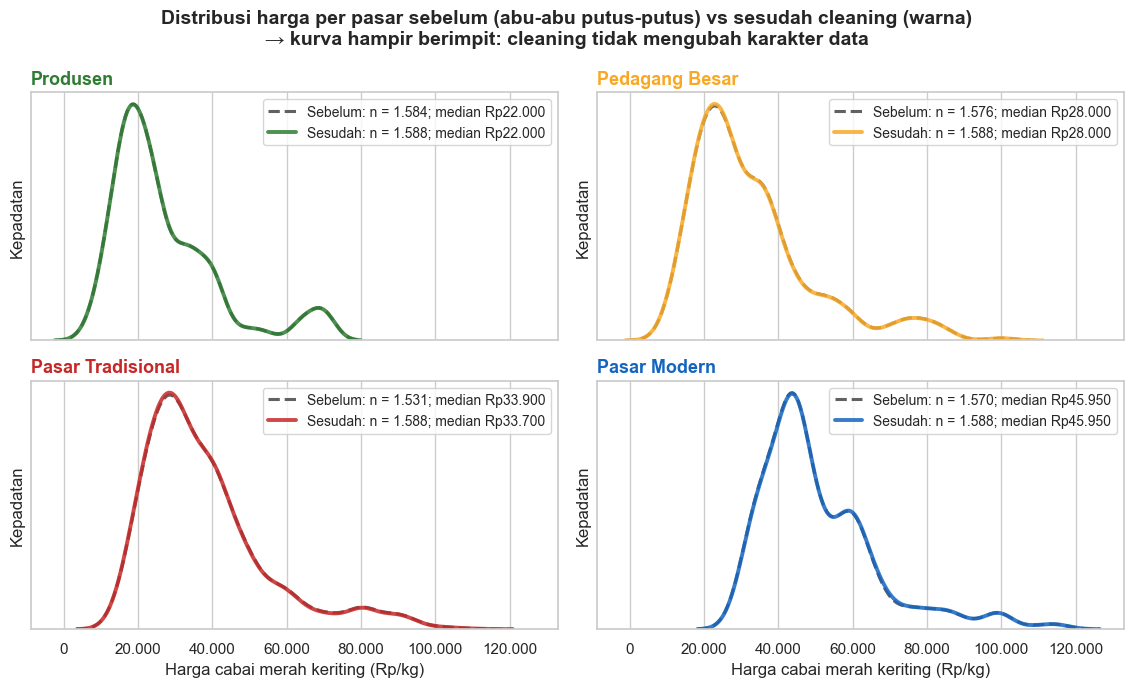

In [26]:
# Distribusi kolom penting sebelum vs sesudah (harga per pasar dalam periode yang sama)
sebelum = mentah.loc[mentah["Tanggal"].between(awal, akhir)].groupby("Kategori_Pasar")["Harga_num"].describe()[["count", "mean", "50%", "std", "min", "max"]]
sesudah = bersih.groupby("Kategori_Pasar", observed=True)["Harga_Cabai_Merah_Keriting"].describe()[["count", "mean", "50%", "std", "min", "max"]]
dist = pd.concat({"Sebelum": sebelum.reindex(PASAR), "Sesudah": sesudah.reindex(PASAR)}, axis=1).round(0)
display(dist)
geser_median = (sesudah["50%"] - sebelum["50%"]).reindex(PASAR)
geser_mean_pct = ((sesudah["mean"] / sebelum["mean"] - 1) * 100).reindex(PASAR).round(2)
print("Pergeseran median (Rp):", geser_median.to_dict())
print("Pergeseran mean (%):", geser_mean_pct.to_dict())

fig, axes = plt.subplots(2, 2, figsize=(11.5, 7), sharex=True)
for ax, m in zip(axes.flat, PASAR):
    s0 = mentah.loc[(mentah["Kategori_Pasar"] == m) & mentah["Tanggal"].between(awal, akhir), "Harga_num"].dropna()
    s1 = bersih.loc[bersih["Kategori_Pasar"] == m, "Harga_Cabai_Merah_Keriting"]
    rb = lambda v: f"{v:,.0f}".replace(",", ".")
    sns.kdeplot(s0, ax=ax, color="#616161", ls="--", lw=2.2, label=f"Sebelum: n = {rb(len(s0))}; median Rp{rb(s0.median())}")
    sns.kdeplot(s1, ax=ax, color=WARNA[m], lw=2.8, alpha=.85, label=f"Sesudah: n = {rb(len(s1))}; median Rp{rb(s1.median())}")
    ax.set_title(m, loc="left", color=WARNA[m]); ax.set_ylabel("Kepadatan"); ax.set_yticks([])
    ax.set_xlabel("Harga cabai merah keriting (Rp/kg)"); ax.xaxis.set_major_formatter(RIBUAN); ax.legend(loc="upper right")
fig.suptitle("Distribusi harga per pasar sebelum (abu-abu putus-putus) vs sesudah cleaning (warna)\n→ kurva hampir berimpit: cleaning tidak mengubah karakter data",
             fontweight="bold", fontsize=14)
plt.tight_layout(); plt.savefig(FIG / "01_distribusi_sebelum_sesudah.png")
plt.show()

**Bukti dampak cleaning (sebelum vs sesudah):**

| Unsur | Penjelasan |
|---|---|
| **Apa** | Membandingkan ukuran data, persentase missing, dan distribusi harga per pasar sebelum dan sesudah cleaning, pada periode yang sama. |
| **Mengapa** | Cleaning yang baik menghilangkan masalah **tanpa mengubah karakter data**. |
| **Arti** | Missing turun dari **18,88% menjadi 0%**, dan semua kolom harga kini bertipe angka. Median harga **tidak bergeser** di Produsen, Pedagang Besar, dan Pasar Modern. Di Pasar Tradisional median hanya bergeser **−Rp200**, dan pergeseran mean di semua pasar ≤ 0,56%. Kurva distribusi sebelum dan sesudah hampir berimpit. |
| **Pengaruh** | Dataset bersih **6.352 baris × 10 kolom** (`01_clean.csv`) siap dipakai untuk EDA. Data cuaca harian kalender (`01_cuaca_harian.csv`) ikut disimpan karena akumulasi hujan di Tahap 3 dihitung dari hari kalender, termasuk Sabtu–Minggu. |

In [27]:
bersih.to_csv(PROC / "01_clean.csv", index=False)
cuaca_bersih = cuaca[(cuaca["Tanggal"] >= awal - pd.Timedelta(days=180)) & (cuaca["Tanggal"] <= akhir)]
cuaca_bersih.to_csv(PROC / "01_cuaca_harian.csv", index=False)

ringkasan = {
    "baris_mentah": int(len(mentah)), "kolom_mentah": int(mentah.drop(columns=["Tanggal", "Harga_num"]).shape[1]),
    "baris_bersih": int(len(bersih)), "kolom_bersih": int(bersih.shape[1]),
    "periode_awal": f"{awal:%Y-%m-%d}", "periode_akhir": f"{akhir:%Y-%m-%d}", "hari_kerja": int(bersih["Tanggal"].nunique()),
    "baris_dibuang_periode": int(luar.sum()), "missing_mentah": int(mentah["Harga_num"].isna().sum()),
    "persen_missing_mentah": round(float(mentah["Harga_num"].isna().mean() * 100), 2),
    "imputasi_ffill": {k: int(v) for k, v in n_imp.items()}, "imputasi_total": int(bersih["Is_Imputasi"].sum()),
    "persen_kosong_terkait_libur": mekanisme.set_index("Pasar")["% terkait libur"].to_dict(), "base_rate_libur": round(float(base_rate), 1),
    "uji_imputasi_mae": uji_imputasi["MAE (Rp/kg)"].to_dict(), "spike_error": int(len(spikes)),
    "outlier_iqr_harga": {k: int(v) for k, v in out_harga["outlier_IQR"].items()},
    "outlier_z_harga": {k: int(v) for k, v in out_harga["outlier_Z>3"].items()},
    "pelanggaran_domain": int(domain["jumlah_pelanggaran"].sum()),
    "sel_teks_berkoma": int(contoh_format["Jumlah terdampak"].iloc[1]),
    "sama_induk_persen": sama_induk.to_dict(),
    "missing_per_kolom_mentah": audit["TOTAL missing"].to_dict(),
    "missing_per_format": audit[list(FORMAT_MISSING)].sum().to_dict(),
    "missing_per_pasar": rinci_pasar[["Harga_Keriting_teks = '-'", "Harga_Agregat_teks = '-'", "implisit (tanggal tidak ada di file)"]].astype(int).to_dict(orient="index"),
    "missing_agregat_mentah": int(kosong_a.sum()),
    "imputasi_ffill_agregat": {k: int(v) for k, v in n_imp_agregat.items()},
    "langkah_log_cleaning": int(len(log_df)),
}
(PROC / "01_ringkasan.json").write_text(json.dumps(ringkasan, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(ringkasan, indent=2, ensure_ascii=False))
print("\nTersimpan:", PROC / "01_clean.csv", bersih.shape, "|", PROC / "01_cuaca_harian.csv", cuaca_bersih.shape)

{
  "baris_mentah": 10437,
  "kolom_mentah": 11,
  "baris_bersih": 6352,
  "kolom_bersih": 10,
  "periode_awal": "2019-12-31",
  "periode_akhir": "2026-01-29",
  "hari_kerja": 1588,
  "baris_dibuang_periode": 4085,
  "missing_mentah": 1970,
  "persen_missing_mentah": 18.88,
  "imputasi_ffill": {
    "Produsen": 4,
    "Pedagang Besar": 12,
    "Pasar Tradisional": 57,
    "Pasar Modern": 18
  },
  "imputasi_total": 92,
  "persen_kosong_terkait_libur": {
    "Produsen": 75.0,
    "Pedagang Besar": 58.3,
    "Pasar Tradisional": 98.2,
    "Pasar Modern": 16.7
  },
  "base_rate_libur": 20.7,
  "uji_imputasi_mae": {
    "Forward-fill per pasar": 1469.0,
    "Interpolasi linear per pasar": 1189.0,
    "Median per pasar": 12010.0,
    "Median global": 13817.0
  },
  "spike_error": 1,
  "outlier_iqr_harga": {
    "Produsen": 108,
    "Pedagang Besar": 100,
    "Pasar Tradisional": 94,
    "Pasar Modern": 70
  },
  "outlier_z_harga": {
    "Produsen": 0,
    "Pedagang Besar": 20,
    "Pasar Tr

## Ringkasan Tahap 1
- **Mentah → bersih:** 10.437 × 11 → **6.352 × 10**, periode 31-12-2019 s.d. 29-01-2026 (1.588 hari kerja × 4 pasar).
- **Missing (format & kolom):** satu-satunya format missing adalah **teks `'-'`**, hanya di **2 kolom harga**:
  `Harga_Keriting_teks` 1.970 sel (18,88%) dan `Harga_Agregat_teks` 1.995 sel (19,11%), ditambah 3 sel implisit
  (tanggal 21-10-2026 hanya di file Produsen). NaN, string kosong, `'nan'`, dan harga 0 = 0 sel. 9 kolom lain lengkap.
- **Penanganan missing:** 4.085 baris di luar periode irisan dibuang (memuat 1.879 sel keriting & 1.880 sel agregat
  kosong). Sisa kekosongan di dalam periode diisi forward-fill per pasar: 91 harga keriting & 115 harga agregat
  (98,2% kekosongan Pasar Tradisional terkait libur nasional). Hasil: **0% missing**.
- **Duplikat:** 0 baris. 1 kolom kembar (`rain_sum`) dihapus. Harga agregat ditandai sebagai kandidat leakage.
- **Format:** 16.909 sel harga teks diubah ke angka, tanggal teks berspasi ke `datetime`, dan nama komoditas dirapikan.
- **Domain:** 0 pelanggaran dari 9 aturan. **Outlier:** 1 salah ketik diperbaiki, 372 lonjakan harga sah dipertahankan.
- **Log:** 16 langkah tercatat di `../laporan/log_cleaning.csv`.

**Lanjut ke `02_eda.ipynb`**, yang membaca `../data/processed/01_clean.csv`.

> ⚠️ Jangan membuka lalu menyimpan ulang file CSV di `data/processed/` dengan Excel. Excel (locale Indonesia) mengubah
> pemisah menjadi `;` dan merusak angka desimal, sehingga notebook berikutnya gagal membaca file.